# Gradient Boosting Regression — Step-by-Step Jupyter Notebook

**Learning objectives**
1. Reproduce the **three-tree classroom example** using `GradientBoostingRegressor`.
2. See the **initial mean prediction**, residuals, tree splits, and learning-rate updates.
3. Train and evaluate Gradient Boosting on the **built-in Diabetes regression dataset**.
4. Tune basic hyperparameters using `GridSearchCV`.

The code is intentionally simple. Run each cell in sequence. No external dataset download is required.

## Part A — Our manual classroom example

We have six machines. We want to predict the number of units produced from operating hours.

**Settings:** 3 trees (`n_estimators=3`), one split per tree (`max_depth=1`), and a learning rate of 0.5. We use squared-error loss.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Classroom dataset
df = pd.DataFrame({
    "Hours": [1, 2, 3, 4, 5, 6],
    "Units": [20, 20, 20, 40, 40, 100]
})

X = df[["Hours"]]  # Must remain 2D
y = df["Units"]

print(df.to_string(index=False))

 Hours  Units
     1     20
     2     20
     3     20
     4     40
     5     40
     6    100


### Step 1 — Initial prediction = mean

For **squared-error regression**, the best single constant prediction is the mean target value. This is **before** fitting any correction trees.

In [2]:
initial_prediction = y.mean()
df["Initial_Prediction"] = initial_prediction
df["Initial_Residual"] = y - initial_prediction

print("Initial prediction (mean):", initial_prediction)
print(df.to_string(index=False))

Initial prediction (mean): 40.0
 Hours  Units  Initial_Prediction  Initial_Residual
     1     20                40.0             -20.0
     2     20                40.0             -20.0
     3     20                40.0             -20.0
     4     40                40.0               0.0
     5     40                40.0               0.0
     6    100                40.0              60.0


### Step 2 — Train the three correction trees

- The **first tree** learns the initial residuals.
- Subsequent trees learn the remaining residuals after previous corrections.
- Every tree's contribution is multiplied by the **learning rate**.

In [3]:
model = GradientBoostingRegressor(
    n_estimators=3,
    learning_rate=0.5,
    max_depth=1,
    loss="squared_error",
    random_state=42
)

model.fit(X, y)
print("Model trained successfully!")

Model trained successfully!


### Step 3 — Predictions after each tree

`staged_predict()` shows the **combined model prediction** after each boosting stage (not the raw output of only that tree).

In [4]:
result = pd.DataFrame({
    "Hours": X["Hours"],
    "Actual": y,
    "Initial": initial_prediction
})

for stage, predictions in enumerate(model.staged_predict(X), start=1):
    result[f"After_Tree_{stage}"] = predictions

print(result.round(2).to_string(index=False))

 Hours  Actual  Initial  After_Tree_1  After_Tree_2  After_Tree_3
     1      20     40.0          34.0          27.0          24.7
     2      20     40.0          34.0          27.0          24.7
     3      20     40.0          34.0          27.0          24.7
     4      40     40.0          34.0          41.0          38.7
     5      40     40.0          34.0          41.0          38.7
     6     100     40.0          70.0          77.0          88.5


### Step 4 — Examine each tree's split and leaf corrections

Because `max_depth=1`, each tree has one split. The leaf values are **corrections**, not final predictions.

In [5]:
for i, estimators_at_stage in enumerate(model.estimators_, start=1):
    tree = estimators_at_stage[0]  # One regression tree per stage for regression
    root = tree.tree_
    split = root.threshold[0]
    left_node = root.children_left[0]
    right_node = root.children_right[0]
    left_correction = root.value[left_node][0][0]
    right_correction = root.value[right_node][0][0]

    print(f"Tree {i}: split Hours <= {split:.1f}")
    print(f"  Left leaf correction:  {left_correction:.2f}")
    print(f"  Right leaf correction: {right_correction:.2f}")
    print()

Tree 1: split Hours <= 5.5
  Left leaf correction:  -12.00
  Right leaf correction: 60.00

Tree 2: split Hours <= 3.5
  Left leaf correction:  -14.00
  Right leaf correction: 14.00

Tree 3: split Hours <= 5.5
  Left leaf correction:  -4.60
  Right leaf correction: 23.00



### Step 5 — Check residuals and MSE at each stage

The residuals for the next tree are `Actual − Current prediction`. For this small training example, we expect the training MSE to decrease over the three stages.

In [6]:
previous_prediction = np.full(len(y), initial_prediction, dtype=float)
print(f"Initial MSE: {mean_squared_error(y, previous_prediction):.2f}")

for stage, current_prediction in enumerate(model.staged_predict(X), start=1):
    residual = y.to_numpy() - current_prediction
    print(f"\nAfter Tree {stage}:")
    print("Predictions:", np.round(current_prediction, 2))
    print("Residuals:  ", np.round(residual, 2))
    print(f"MSE: {mean_squared_error(y, current_prediction):.2f}")
    previous_prediction = current_prediction

Initial MSE: 800.00

After Tree 1:
Predictions: [34. 34. 34. 34. 34. 70.]
Residuals:   [-14. -14. -14.   6.   6.  30.]
MSE: 260.00

After Tree 2:
Predictions: [27. 27. 27. 41. 41. 77.]
Residuals:   [-7. -7. -7. -1. -1. 23.]
MSE: 113.00

After Tree 3:
Predictions: [24.7 24.7 24.7 38.7 38.7 88.5]
Residuals:   [-4.7 -4.7 -4.7  1.3  1.3 11.5]
MSE: 33.65


### Step 6 — Plot actual values and stage-wise predictions

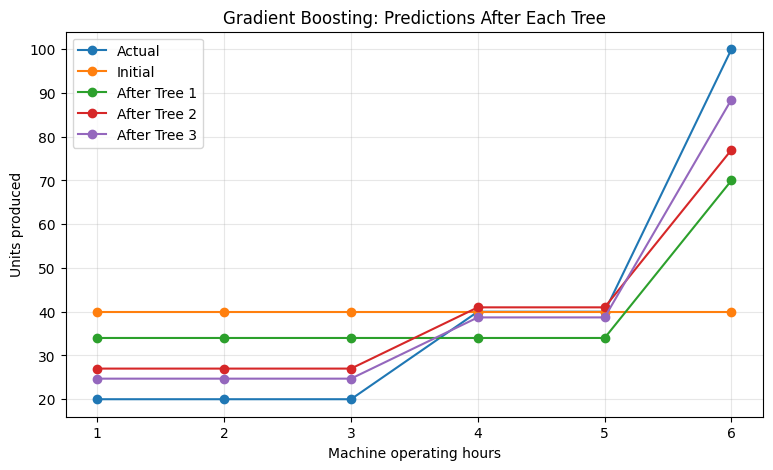

In [7]:
plt.figure(figsize=(9, 5))
plt.plot(X["Hours"], y, marker="o", label="Actual")
plt.plot(X["Hours"], np.full(len(y), initial_prediction), marker="o", label="Initial")

for stage, predictions in enumerate(model.staged_predict(X), start=1):
    plt.plot(X["Hours"], predictions, marker="o", label=f"After Tree {stage}")

plt.xlabel("Machine operating hours")
plt.ylabel("Units produced")
plt.title("Gradient Boosting: Predictions After Each Tree")
plt.xticks(X["Hours"])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Step 7 — Predict for a new observation

A tree predicts a **constant value in each leaf**. Thus, new observations receive the correction assigned to their leaves. Gradient Boosting adds all the scaled corrections to the initial prediction.

In [8]:
new_data = pd.DataFrame({"Hours": [4, 6]})
new_data["Predicted_Units"] = model.predict(new_data)
print(new_data.round(2).to_string(index=False))

 Hours  Predicted_Units
     4             38.7
     6             88.5


---
## Part B — A real dataset: Diabetes regression

The built-in `load_diabetes` dataset contains **442 observations and 10 numerical features**. The target is a quantitative measure of disease progression one year after baseline. The purpose here is demonstrating a **regression workflow**, not giving medical advice.

**Important:** We train on the training set and evaluate on the test set. We do not use the test set for hyperparameter tuning.

In [9]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV

# Load a built-in regression dataset
diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target

print("Features:", X.shape)
print("Target:", y.shape)
print(X.head())

Features: (442, 10)
Target: (442,)
        age       sex       bmi  ...        s4        s5        s6
0  0.038076  0.050680  0.061696  ... -0.002592  0.019907 -0.017646
1 -0.001882 -0.044642 -0.051474  ... -0.039493 -0.068332 -0.092204
2  0.085299  0.050680  0.044451  ... -0.002592  0.002861 -0.025930
3 -0.089063 -0.044642 -0.011595  ...  0.034309  0.022688 -0.009362
4  0.005383 -0.044642 -0.036385  ... -0.002592 -0.031988 -0.046641

[5 rows x 10 columns]


### Step 8 — Train/test split and baseline model

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

baseline_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

baseline_model.fit(X_train, y_train)
y_pred = baseline_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE:  {mse:.2f}")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test R²:   {r2:.3f}")

Test MSE:  2898.44
Test RMSE: 53.84
Test R²:   0.453


### Step 9 — Plot actual vs predicted values

Points nearer the diagonal have predictions closer to actual target values.

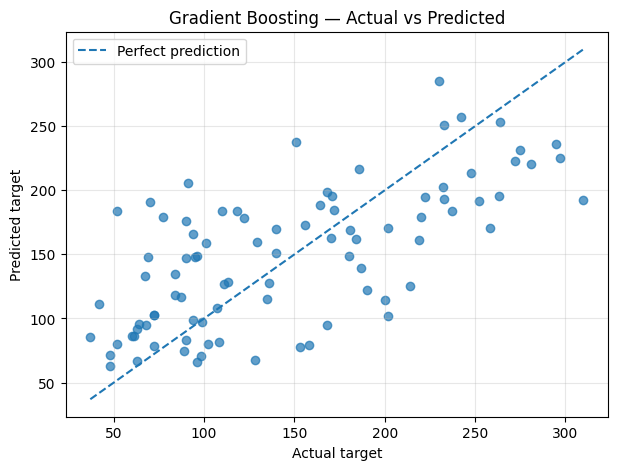

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], linestyle="--", label="Perfect prediction")

plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Gradient Boosting — Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Step 10 — Tune the hyperparameters using GridSearchCV

This small search is intentionally limited so it runs comfortably during class. `neg_root_mean_squared_error` is negative because scikit-learn treats **higher scores as better**. To report RMSE, change the sign back to positive.

In [12]:
param_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3],
    "subsample": [0.8, 1.0]
}

grid = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation RMSE:", round(-grid.best_score_, 2))

Best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 50, 'subsample': 0.8}
Best cross-validation RMSE: 57.48


### Step 11 — Evaluate the best tuned model on the test set

In [13]:
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)

print("Baseline test RMSE:", round(rmse, 2))
print("Tuned test RMSE:   ", round(np.sqrt(mean_squared_error(y_test, best_pred)), 2))
print("Tuned test R²:     ", round(r2_score(y_test, best_pred), 3))

Baseline test RMSE: 53.84
Tuned test RMSE:    52.38
Tuned test R²:      0.482


### Step 12 — Inspect feature importance

Tree feature importance reports how much the model relied on features for reducing split impurity. It does **not** prove causation.

bmi    0.413
s5     0.274
bp     0.104
s2     0.048
s3     0.043
age    0.040
s6     0.026
s4     0.024
s1     0.018
sex    0.011
dtype: float64


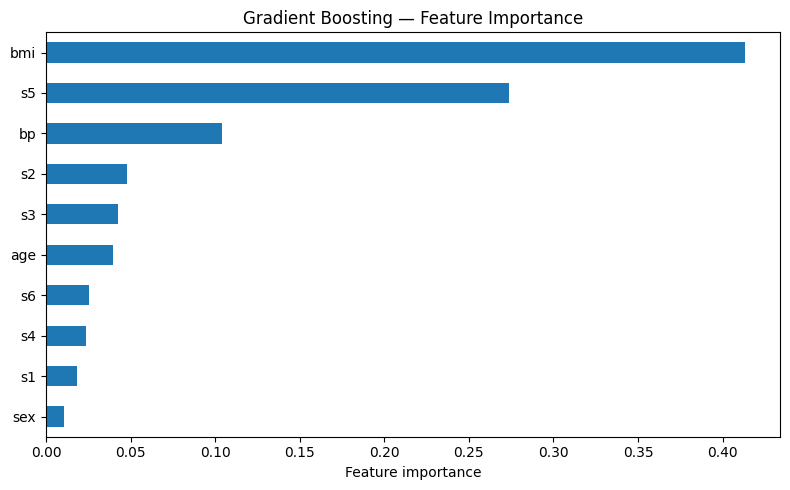

In [14]:
importance = pd.Series(
    best_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.round(3))

plt.figure(figsize=(8, 5))
importance.sort_values().plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Gradient Boosting — Feature Importance")
plt.tight_layout()
plt.show()

### Student practice

1. In **Part A**, change `learning_rate` to `1.0`. How do the stage-wise predictions change?
2. In **Part A**, change `max_depth` to `2`. Do all tree splits remain the same? Why might not?
3. In **Part B**, compare `n_estimators=50` and `n_estimators=200` on the same train/test split.
4. In **Part B**, explain in one sentence what `subsample=0.8` means.
5. In **Part B**, why should we select hyperparameters using cross-validation on **training data**, rather than the test set?

**Key takeaway:** Gradient Boosting starts with a simple prediction and learns a sequence of regression trees to correct prediction errors. For squared-error loss, these corrections are based on residuals.